# Compressor Health Clustering

## 1. Condition Monitoring and Retrospective Event Review

This notebook uses the saved K-Means pipeline and window assignments from notebook 03 to summarize operating-state frequencies, cluster transitions, and unusually distant windows. It also compares the recorded air-leak/high-stress periods from the supplied dataset description with the historical assignments.

The current saved pipeline uses **provisional k=4**. Notebook 03 found that k=3 had the strongest sampled silhouette, that two k=4 cluster profiles were nearly identical, and that one cluster nearly disappeared in the chronological holdout. Treat every result here as exploratory until k is reviewed. A cluster change or distance alert is unusual behavior, not a confirmed fault. This is an offline historical analysis, not live monitoring.

## 2. Load the Saved Artifacts

Read the processed features, window metadata, assignments, and fitted pipeline generated by notebook 03. No model is retrained here.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_RELATIVE_PATH = Path("data") / "processed" / "metropt_window_clusters_5min.csv"
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / DATA_RELATIVE_PATH).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Saved cluster assignments were not found. Run notebook 03 and save its outputs first."
    )
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FEATURE_PATH = PROCESSED_DIR / "metropt_window_features_5min.csv"
METADATA_PATH = PROCESSED_DIR / "metropt_window_metadata_5min.csv"
ASSIGNMENTS_PATH = PROCESSED_DIR / "metropt_window_clusters_5min.csv"
MODEL_PATH = MODEL_DIR / "kmeans_pipeline_5min.joblib"
MODEL_METADATA_PATH = MODEL_DIR / "kmeans_metadata_5min.json"
required_paths = [FEATURE_PATH, METADATA_PATH, ASSIGNMENTS_PATH, MODEL_PATH, MODEL_METADATA_PATH]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError("Required notebook 03 artifacts are missing: " + ", ".join(missing_paths))

PALETTE = {
    "blue": "#72B7F2", "teal": "#4FD1C5", "amber": "#F6C177",
    "red": "#F28B82", "gray": "#AAB6C2", "figure_bg": "#151B23",
    "axes_bg": "#202833", "text": "#E6EDF3", "muted_text": "#B8C4D0",
    "grid": "#3B4653",
}
sns.set_theme(style="darkgrid", context="notebook", font="DejaVu Sans", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (11, 5), "figure.dpi": 120,
    "figure.facecolor": PALETTE["figure_bg"], "savefig.facecolor": PALETTE["figure_bg"],
    "axes.facecolor": PALETTE["axes_bg"], "axes.edgecolor": PALETTE["grid"],
    "axes.labelcolor": PALETTE["text"], "axes.titlecolor": PALETTE["text"],
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": PALETTE["muted_text"], "ytick.color": PALETTE["muted_text"],
    "text.color": PALETTE["text"], "grid.color": PALETTE["grid"], "grid.alpha": 0.55,
})
print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Projects_Tracking\Compressor_Health_Clustering


## 3. Join Assignments to Their Window Features

The metadata table contains all windows; the assignment table contains only windows that passed notebook 03's coverage filter. Unassigned low-coverage windows remain visible as missing cluster labels and are not treated as normal states.

In [2]:
KEYS = ["segment_id", "window_id"]
features = pd.read_csv(FEATURE_PATH)
metadata = pd.read_csv(METADATA_PATH, parse_dates=["window_start", "window_end"])
assignments = pd.read_csv(ASSIGNMENTS_PATH, parse_dates=["window_start", "window_end"])
model_metadata = json.loads(MODEL_METADATA_PATH.read_text(encoding="utf-8"))
pipeline = joblib.load(MODEL_PATH)
FEATURE_COLUMNS = model_metadata["feature_columns"]

if any(column not in features.columns for column in [*KEYS, *FEATURE_COLUMNS]):
    raise ValueError("The feature CSV does not match the saved model feature schema.")
if int(model_metadata["provisional_k"]) != pipeline.named_steps["kmeans"].n_clusters:
    raise ValueError("Model metadata and saved pipeline disagree about k.")

windows = metadata.merge(features, on=KEYS, how="inner", validate="one_to_one")
assignment_columns = [*KEYS, "cluster", "partition"]
windows = windows.merge(
    assignments[assignment_columns], on=KEYS, how="left", validate="one_to_one"
).sort_values(["window_start", "segment_id", "window_id"]).reset_index(drop=True)
windows["cluster"] = pd.to_numeric(windows["cluster"], errors="coerce").astype("Int64")
assigned = windows.dropna(subset=["cluster"]).copy()
assigned["cluster"] = assigned["cluster"].astype(int)
assigned = assigned.sort_values(["window_start", "segment_id", "window_id"]).reset_index(drop=True)
CLUSTERS = sorted(assigned["cluster"].unique().tolist())
K = int(model_metadata["provisional_k"])
print(f"All windows: {len(windows):,} | Assigned windows: {len(assigned):,} | k={K}")
print(f"Unassigned windows retained for review: {windows['cluster'].isna().sum():,}")
display(assigned[[*KEYS, "window_start", "coverage_fraction", "partition", "cluster"]].head())

All windows: 50,584 | Assigned windows: 50,437 | k=4
Unassigned windows retained for review: 147


,segment_id,window_id,window_start,coverage_fraction,partition,cluster
0,0,0,2020-02-01 00:00:00,1.0,train,0
1,0,1,2020-02-01 00:05:07,1.0,train,0
2,0,2,2020-02-01 00:10:04,1.0,train,0
3,0,3,2020-02-01 00:15:02,1.0,train,0
4,0,4,2020-02-01 00:20:09,1.0,train,0


## 4. Verify Saved Assignments and Score Distance to the Nearest Center

Recompute predictions from the saved pipeline to verify that the assignment CSV matches the model. The minimum center distance is a relative unusualness measure in the fitted feature space, not a probability or health score.

In [3]:
saved_labels = assigned["cluster"].to_numpy(dtype=int)
model_labels = pipeline.predict(assigned[FEATURE_COLUMNS])
if not np.array_equal(saved_labels, model_labels):
    raise ValueError("Saved labels do not match the loaded pipeline predictions.")

center_distances = pipeline.transform(assigned[FEATURE_COLUMNS])
assigned["nearest_center_distance"] = center_distances.min(axis=1)
print(f"Saved assignments match pipeline predictions for {len(assigned):,} windows.")
display(assigned.groupby(["partition", "cluster"]).size().rename("windows").to_frame())

Saved assignments match pipeline predictions for 50,437 windows.


windows
partition cluster         
holdout   0           9609
          1              8
          2            262
          3            209
train     0          35806
          1           2935
          2            663
          3            945

## 5. Compare Cluster Frequencies Over the Chronological Split

The cluster distribution already shifts strongly between training and holdout in notebook 03. Review that change before interpreting a rare cluster as an alert.

cluster,0,1,2,3
partition,,,,
train,35806,2935,663,945
holdout,9609,8,262,209


cluster,0,1,2,3
partition,,,,
train,88.74,7.27,1.64,2.34
holdout,95.25,0.08,2.60,2.07


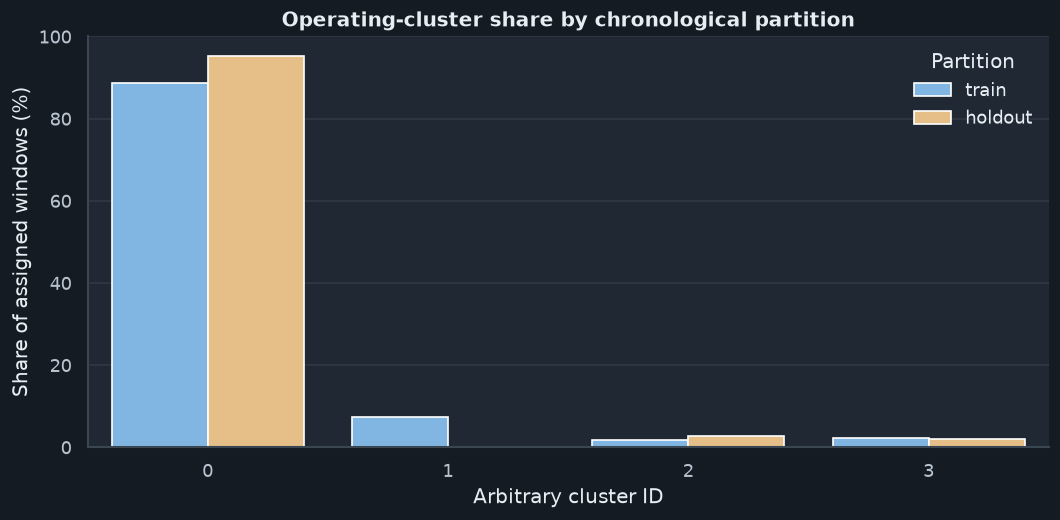

In [4]:
cluster_counts = pd.crosstab(assigned["partition"], assigned["cluster"]).reindex(
    index=["train", "holdout"], columns=range(K), fill_value=0
)
cluster_shares = cluster_counts.div(cluster_counts.sum(axis=1), axis=0) * 100
display(cluster_counts.rename_axis(columns="cluster").round(0).astype(int))
display(cluster_shares.rename_axis(columns="cluster").round(2))

share_plot = cluster_shares.rename_axis(columns="cluster").reset_index().melt(
    id_vars="partition", var_name="cluster", value_name="share_percent"
)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=share_plot, x="cluster", y="share_percent", hue="partition",
            palette=[PALETTE["blue"], PALETTE["amber"]], ax=ax)
ax.set(title="Operating-cluster share by chronological partition",
       xlabel="Arbitrary cluster ID", ylabel="Share of assigned windows (%)")
ax.legend(title="Partition", frameon=False)
fig.tight_layout()
plt.show()

## 6. Add the Documented Event Periods

These dates are transcribed from the supplied dataset description. They are retrospective annotations only and are not clustering inputs. The source has an inconsistent maintenance note for event 2 (it says April 30 although the air-leak period is May 29-30); do not use that maintenance time until it is verified.

In [5]:
events = pd.DataFrame([
    {"event_id": "event_1", "event_type": "air leak / high stress",
     "start": "2020-04-18 00:00:00", "end": "2020-04-18 23:59:00"},
    {"event_id": "event_2", "event_type": "air leak / high stress",
     "start": "2020-05-29 23:30:00", "end": "2020-05-30 06:00:00"},
    {"event_id": "event_3", "event_type": "air leak / high stress",
     "start": "2020-06-05 10:00:00", "end": "2020-06-07 14:30:00"},
    {"event_id": "event_4", "event_type": "air leak / high stress",
     "start": "2020-07-15 14:30:00", "end": "2020-07-15 19:00:00"},
])
events["start"] = pd.to_datetime(events["start"])
events["end"] = pd.to_datetime(events["end"])
display(events)

def event_overlap_mask(frame, event_table):
    """Return True for windows overlapping any documented event period."""
    mask = pd.Series(False, index=frame.index)
    for event in event_table.itertuples(index=False):
        mask |= (frame["window_start"] <= event.end) & (frame["window_end"] >= event.start)
    return mask

def event_ids_for_windows(frame, event_table):
    """Return semicolon-separated event IDs for overlapping windows."""
    labels = pd.Series("", index=frame.index, dtype="object")
    for event in event_table.itertuples(index=False):
        overlap = (frame["window_start"] <= event.end) & (frame["window_end"] >= event.start)
        labels.loc[overlap] = labels.loc[overlap].map(
            lambda value: f"{value};{event.event_id}" if value else event.event_id
        )
    return labels

assigned["reported_event_ids"] = event_ids_for_windows(assigned, events)
assigned["overlaps_reported_event"] = assigned["reported_event_ids"].ne("")
print(f"Assigned windows overlapping a reported event: {assigned['overlaps_reported_event'].sum():,}")

,event_id,event_type,start,end
0,event_1,air leak / high stress,2020-04-18 00:00:00,2020-04-18 23:59:00
1,event_2,air leak / high stress,2020-05-29 23:30:00,2020-05-30 06:00:00
2,event_3,air leak / high stress,2020-06-05 10:00:00,2020-06-07 14:30:00
3,event_4,air leak / high stress,2020-07-15 14:30:00,2020-07-15 19:00:00


Assigned windows overlapping a reported event: 991


## 7. Set a Transparent Distance Threshold from Non-Event Training Windows

For an exploratory alert, use the 99th percentile of nearest-center distances within each cluster, calibrated only on training windows that do not overlap the documented event dates. This threshold is a review rule, not a validated alarm limit. If a cluster has too few clean reference windows, suppress its threshold-based alert and report that limitation.

In [6]:
train_mask = assigned["partition"].eq("train")
calibration = assigned.loc[train_mask & ~assigned["overlaps_reported_event"]].copy()
threshold_rows = []
threshold_by_cluster = {}
for cluster in range(K):
    values = calibration.loc[calibration["cluster"] == cluster, "nearest_center_distance"]
    if len(values) < 100:
        threshold_by_cluster[cluster] = np.inf
        threshold_rows.append({"cluster": cluster, "reference_windows": len(values),
                              "p99_distance_threshold": np.inf, "threshold_available": False})
    else:
        threshold = float(values.quantile(0.99))
        threshold_by_cluster[cluster] = threshold
        threshold_rows.append({"cluster": cluster, "reference_windows": len(values),
                              "p99_distance_threshold": threshold, "threshold_available": True})
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

assigned["distance_threshold"] = assigned["cluster"].map(threshold_by_cluster).astype(float)
assigned["distance_alert"] = assigned["nearest_center_distance"] > assigned["distance_threshold"]
print(f"Distance-alert windows: {int(assigned['distance_alert'].sum()):,}")

,cluster,reference_windows,p99_distance_threshold,threshold_available
0,0,35798,351.782764,True
1,1,1953,921.682728,True
2,2,662,1767.514495,True
3,3,945,737.183670,True


Distance-alert windows: 484


## 8. Require Persistence Before Flagging Unusual Behavior

A single high-distance window may reflect a brief transient. Mark a persistent unusual-behavior episode only when at least three consecutive 5-minute windows exceed their cluster-specific training threshold. Consecutive means same segment and adjacent window IDs; a gap or missing window resets the run.

In [7]:
same_segment = assigned["segment_id"].eq(assigned["segment_id"].shift())
adjacent_window = assigned["window_id"].eq(assigned["window_id"].shift() + 1)
run_break = (~assigned["distance_alert"]) | (~same_segment) | (~adjacent_window)
alert_run_id = run_break.cumsum()
alert_run_length = assigned["distance_alert"].groupby(alert_run_id).transform("sum")
assigned["persistent_unusual_behavior"] = assigned["distance_alert"] & (alert_run_length >= 3)
print(f"Persistent unusual-behavior windows: {int(assigned['persistent_unusual_behavior'].sum()):,}")
print("These flags indicate atypical feature-space distance, not a confirmed equipment fault.")

Persistent unusual-behavior windows: 7
These flags indicate atypical feature-space distance, not a confirmed equipment fault.


## 9. Plot Cluster Timeline and Persistent Unusual Behavior

Show assigned operating clusters over time, persistent unusual windows, and reported event periods. Blank spans reflect lack of assigned observations; the plot does not interpolate across gaps.

In [ ]:
cluster_colors = dict(zip(range(K), sns.color_palette("colorblind", n_colors=K).as_hex()))
fig, ax = plt.subplots(figsize=(14, 5.5))
for cluster, group in assigned.groupby("cluster", sort=True):
    ax.scatter(group["window_start"], group["cluster"], s=7, alpha=0.55,
               color=cluster_colors[cluster], label=f"Cluster {cluster}", linewidths=0)
persistent = assigned.loc[assigned["persistent_unusual_behavior"]]
if not persistent.empty:
    ax.scatter(persistent["window_start"], persistent["cluster"], marker="x", s=30,
               color=PALETTE["red"], label="Persistent unusual behavior", zorder=4)
for event in events.itertuples(index=False):
    ax.axvspan(event.start, event.end, color=PALETTE["red"], alpha=0.12)
ax.set(title="Historical operating-cluster timeline with reported event periods",
       xlabel="Timestamp", ylabel="Arbitrary cluster ID", yticks=list(range(K)))
ax.legend(title="Observed grouping", frameon=False, loc="upper left",
          bbox_to_anchor=(1.01, 1), ncol=1)
fig.tight_layout(rect=(0, 0, 0.87, 1))
plt.show()

## 10. Summarize Cluster Frequencies Over Time

Daily shares reveal persistent state-mix changes more clearly than a dense point-by-point timeline. Days with no assigned observations remain gaps in the lines.

In [ ]:
assigned["day"] = assigned["window_start"].dt.floor("D")
daily_counts = assigned.groupby(["day", "cluster"]).size().unstack("cluster")
all_days = pd.date_range(daily_counts.index.min(), daily_counts.index.max(), freq="D")
daily_counts = daily_counts.reindex(index=all_days, columns=range(K))
has_data = daily_counts.notna().any(axis=1)
daily_counts.loc[has_data] = daily_counts.loc[has_data].fillna(0)
daily_share = daily_counts.div(daily_counts.sum(axis=1), axis=0).where(has_data)

fig, ax = plt.subplots(figsize=(14, 5))
for cluster in range(K):
    ax.plot(daily_share.index, daily_share[cluster], color=cluster_colors[cluster],
            linewidth=1.6, label=f"Cluster {cluster}")
ax.set(title="Daily share of assigned operating windows", xlabel="Date", ylabel="Share of windows")
ax.set_ylim(0, 1)
ax.legend(title="Arbitrary cluster ID", frameon=False, loc="upper left",
          bbox_to_anchor=(1.01, 1), ncol=1)
fig.tight_layout(rect=(0, 0, 0.88, 1))
plt.show()

## 11. Review Cluster Transitions Within Continuous Segments

Count adjacent 5-minute window transitions only when segment IDs match and window IDs are consecutive. Normalize each matrix row to show the next-state distribution conditional on the current cluster.

to cluster,0,1,2,3
from cluster,,,,
0,43103,45,881,1082
1,55,2834,13,24
2,887,14,5,12
3,1101,16,12,21


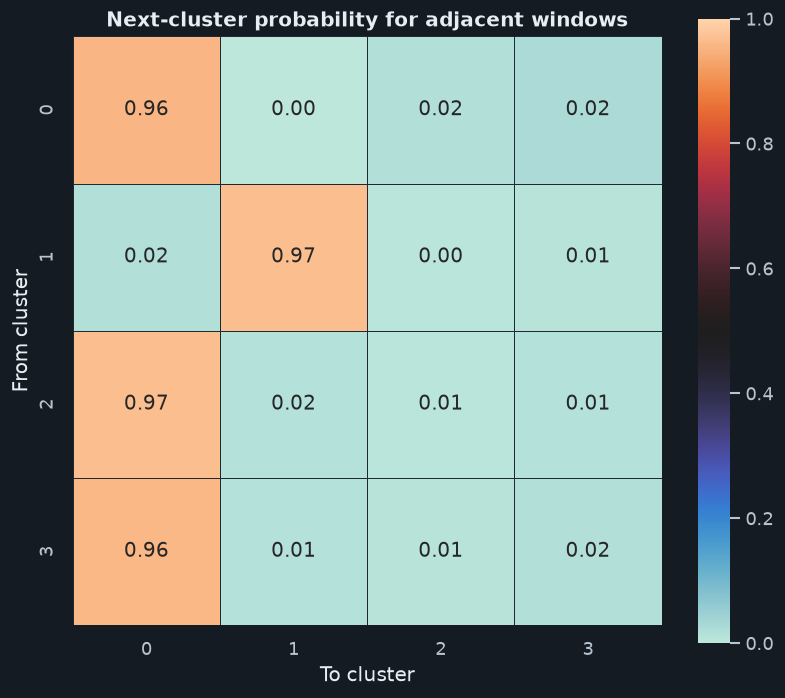

In [10]:
ordered = assigned.sort_values(["segment_id", "window_id"]).copy()
previous_cluster = ordered.groupby("segment_id")["cluster"].shift()
previous_window = ordered.groupby("segment_id")["window_id"].shift()
contiguous = ordered["window_id"].eq(previous_window + 1)
transition_counts = pd.crosstab(previous_cluster[contiguous], ordered.loc[contiguous, "cluster"])
transition_counts = transition_counts.reindex(index=range(K), columns=range(K), fill_value=0)
transition_probabilities = transition_counts.div(transition_counts.sum(axis=1).replace(0, np.nan), axis=0)
display(transition_counts.rename_axis(index="from cluster", columns="to cluster"))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(transition_probabilities, cmap="icefire", vmin=0, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=0.3, linecolor=PALETTE["axes_bg"], ax=ax)
ax.collections[0].colorbar.ax.tick_params(colors=PALETTE["muted_text"])
ax.collections[0].colorbar.outline.set_edgecolor(PALETTE["grid"])
ax.set(title="Next-cluster probability for adjacent windows", xlabel="To cluster", ylabel="From cluster")
fig.tight_layout()
plt.show()

## 12. Compare Reported Event Periods with Clusters and Alerts

For each reported period, summarize overlapping assigned windows, cluster composition, distance flags, and persistent unusual-behavior flags. These are descriptive overlaps. All four reported periods fall in the model's training period, so this is not independent holdout validation.

In [ ]:
event_rows = []
event_cluster_rows = []
for event in events.itertuples(index=False):
    overlap = assigned.loc[
        (assigned["window_start"] <= event.end) & (assigned["window_end"] >= event.start)
    ]
    event_rows.append({
        "event_id": event.event_id,
        "reported_type": event.event_type,
        "start": event.start,
        "end": event.end,
        "overlapping_windows": len(overlap),
        "distance_alert_windows": int(overlap["distance_alert"].sum()),
        "persistent_unusual_windows": int(overlap["persistent_unusual_behavior"].sum()),
        "median_center_distance": overlap["nearest_center_distance"].median(),
    })
    if not overlap.empty:
        counts = overlap["cluster"].value_counts(normalize=True)
        for cluster in range(K):
            event_cluster_rows.append({
                "event_id": event.event_id, "cluster": cluster,
                "window_share_percent": float(counts.get(cluster, 0) * 100),
            })
event_summary = pd.DataFrame(event_rows)
event_cluster_shares = pd.DataFrame(event_cluster_rows)
event_summary_display = event_summary.copy()
event_summary_display["median_center_distance"] = event_summary_display["median_center_distance"].round(3)
display(event_summary_display)
display(event_cluster_shares.pivot(index="event_id", columns="cluster",
                                  values="window_share_percent").fillna(0).round(1))

## 13. Check for Persistent Flags Before Each Reported Event

For context, find the closest persistent unusual-behavior window ending within 24 hours before each event start. This is retrospective and uses a model fitted on the same historical period, so it cannot establish a genuine prospective warning.

In [ ]:
lead_rows = []
for event in events.itertuples(index=False):
    prior = assigned.loc[
        (assigned["window_end"] < event.start)
        & (assigned["window_end"] >= event.start - pd.Timedelta(hours=24))
        & assigned["persistent_unusual_behavior"]
    ].sort_values("window_end")
    if prior.empty:
        lead_rows.append({"event_id": event.event_id,
                          "persistent_flag_in_prior_24h": False,
                          "last_flag_end": "No persistent flag in prior 24 h",
                          "lead_time_hours": "N/A"})
    else:
        last_flag_end = prior["window_end"].max()
        lead_rows.append({"event_id": event.event_id,
                          "persistent_flag_in_prior_24h": True,
                          "last_flag_end": last_flag_end,
                          "lead_time_hours": round((event.start - last_flag_end).total_seconds() / 3600, 2)})
lead_summary = pd.DataFrame(lead_rows)
display(lead_summary)

## 14. Save Monitoring Outputs

Save window-level distances, event overlap IDs, and transparent persistence flags, plus compact event and cluster summaries. These files are historical analysis products, not live alerts.

In [13]:
monitoring_path = PROCESSED_DIR / "metropt_condition_monitoring_5min.csv"
event_summary_path = PROCESSED_DIR / "metropt_reported_event_summary_5min.csv"
transition_path = PROCESSED_DIR / "metropt_cluster_transitions_5min.csv"

monitor_columns = [*KEYS, "window_start", "window_end", "coverage_fraction", "partition",
                   "cluster", "nearest_center_distance", "distance_threshold",
                   "distance_alert", "persistent_unusual_behavior", "reported_event_ids"]
assigned[monitor_columns].to_csv(monitoring_path, index=False)
event_summary.to_csv(event_summary_path, index=False)
transition_probabilities.to_csv(transition_path, index_label="from_cluster")
print(f"Saved window monitoring results: {monitoring_path}")
print(f"Saved event summary: {event_summary_path}")
print(f"Saved transition matrix: {transition_path}")

Saved window monitoring results: c:\Projects_Tracking\Compressor_Health_Clustering\data\processed\metropt_condition_monitoring_5min.csv
Saved event summary: c:\Projects_Tracking\Compressor_Health_Clustering\data\processed\metropt_reported_event_summary_5min.csv
Saved transition matrix: c:\Projects_Tracking\Compressor_Health_Clustering\data\processed\metropt_cluster_transitions_5min.csv


## 15. Findings and Limitations

### Findings from the saved run

- The saved pipeline's predictions match all **50,437 assigned windows**. Another **147 low-coverage windows** remain unassigned and were not treated as cluster states.
- Cluster 0 accounts for **88.74% of training windows** and **95.25% of holdout windows**. Cluster 1 drops from **2,935 training windows** to **8 holdout windows** (0.08%). This is a strong temporal change in the saved model's state mix and should be investigated; it is not itself a fault indication.
- The saved distance rule generated **484 single-window distance alerts**, but only **7 windows** belonged to runs of three consecutive alerts. The persistence rule found no such windows during the four reported events or in the 24 hours before them.
- In section 13, `last_flag_end` and `lead_time_hours` are blank when no persistent flag ended in the preceding 24 hours. These were **expected no-match values**, not missing sensor readings. The display now states “No persistent flag in prior 24 h” and “N/A” explicitly. This means the chosen rule found no persistent lead signal in that lookback period; it does not rule out brief flags, signals outside 24 hours, or other warning criteria.
- The event-overlap table contains **991 assigned windows** across the four reported periods (286, 79, 571, and 55). Cluster 1 dominates each period (about 94.5%-99.8%), but that association is not proof of a fault-specific state. One distance alert occurred during event 3; none of the events contained a persistent alert.
- In the transition matrix, clusters 2 and 3 transition back to cluster 0 in about 96%-97% of adjacent transitions. This supports treating them as brief or transitional groups for follow-up, not automatically as faults.

### Limitations

- The saved k=4 pipeline is provisional: notebook 03 found k=3 had the highest sampled silhouette, and k=4 clusters 2 and 3 had nearly identical profiles. Revisit the cluster count before treating monitoring results as final.
- All four reported event periods fall inside the model's training period. Event comparisons and lead-time checks are therefore retrospective and in-sample, not independent validation or prospective warning evidence.
- Distance thresholds are the 99th percentile within each cluster, calibrated from training windows outside the reported periods. The thresholds are transparent review criteria, not validated alarm limits. The fitted centers still saw the event-period data.
- The event periods are coarse report annotations, not row-level verified labels. The source's May 29-30 maintenance note contains an inconsistent April date.
- The analysis is offline and historical. Cluster changes and distance alerts indicate behavior to review; they do not establish faults, health scores, or failure probabilities.
